# Project 2 -- GCN on brain connectivity

- Class: CSE 6389
- Name: John (chenxi) Song
- ID: 1002306479

# 1. Data Description

The dataset contains brain connectivity data from 20 subjects, including 10 Alzheimer's disease (AD) subjects and 10 cognitively normal (CN) subjects. Each subject contains two $150 \times 150$ connectivity matrices representing relationships among 150 brain regions of interest (ROIs):

- Total 20 Patients: 10 in AD, 10 in CN.
- 150 x 150 matrix
- Structural Connectivity (SC): represents structural connections between pairs of ROIs using streamline counts.
- Functional Connectivity (FC): represents functional relationships between pairs of ROIs using correlation values.

## 1.1 Example of Data

- Example of AD 1 label with FC and SC

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
DATA_ROOT = "/content/drive/MyDrive/6389_data/Project/Project2/6389Project2Data/"

In [44]:
example("FunctionalConnectivity.txt")
example("StructuralConnectivity.txt")

===============FunctionalConnectivity.txt==================
Shape: (150, 150)
Min: -0.39449626
Max: 1.0
Symmetric: True
===============StructuralConnectivity.txt==================
Shape: (150, 150)
Min: 0.0
Max: 5567.0
Symmetric: True


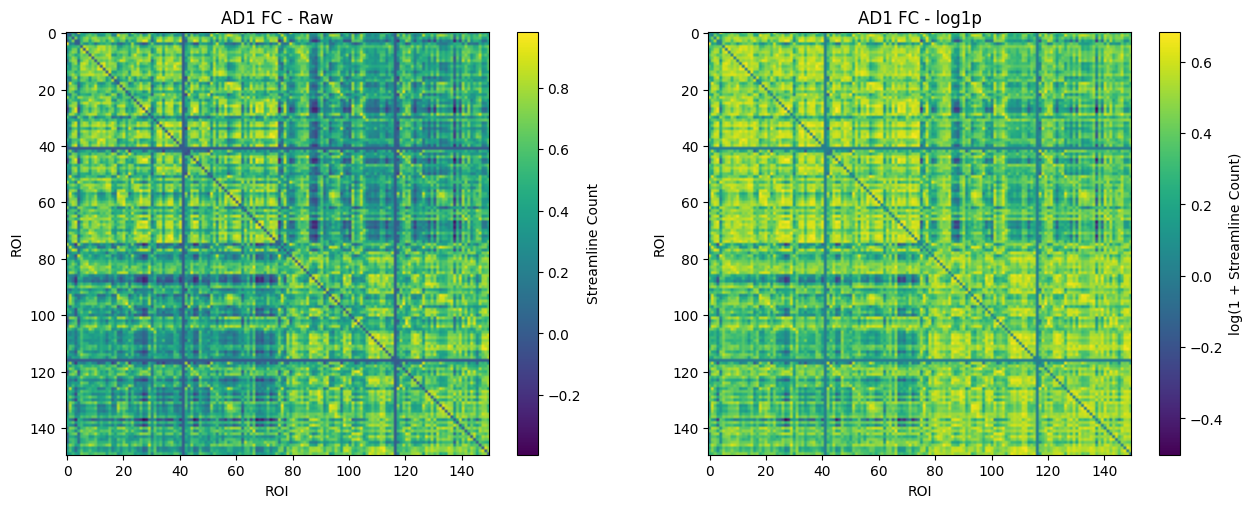

In [45]:
example_graph_comparing("FunctionalConnectivity.txt","FC")

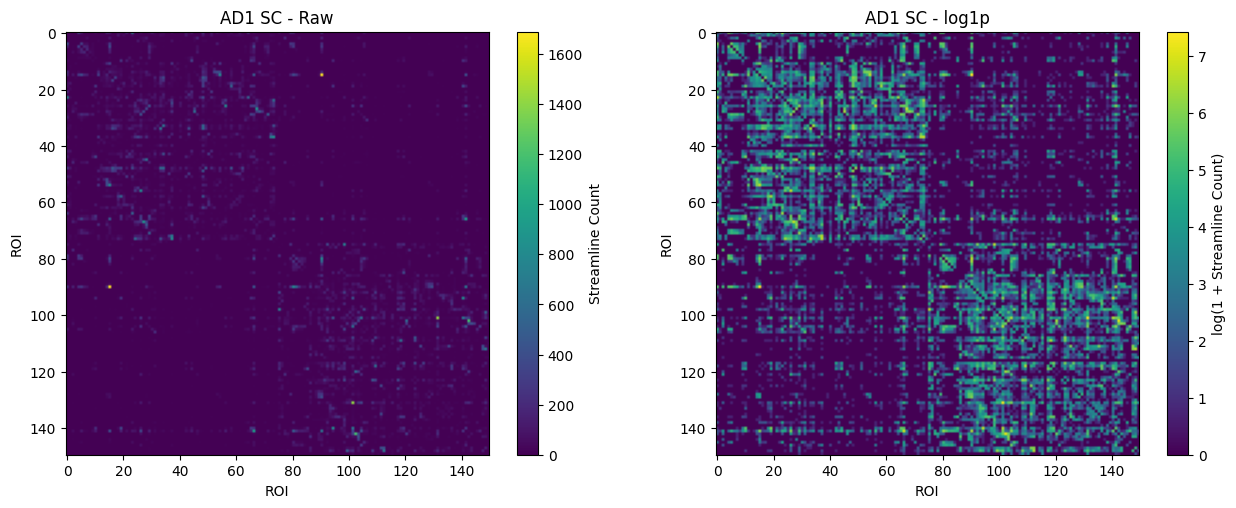

In [46]:
example_graph_comparing("StructuralConnectivity.txt","SC")

# 2. Data Preprocessing (EDA Analysis)


## 2.1 Functional Connectivity Preprocessing

Functional connectivity values are correlation coefficients and are already bounded approximately between (-1) and (1). Therefore, no logarithmic transformation or adjacency normalization was applied to FC.


In [48]:
roi0_features = inspect_fc_node(
    "FunctionalConnectivity.txt",
    subject="AD1",
    roi=0
)

Subject: AD1
ROI: 0
Feature vector shape: (150,)
First 10 values:
[ 1.          0.15504818  0.22021611 -0.06020348  0.96273618  0.45372703
  0.22526109  0.2020121   0.42222928  0.31547085]


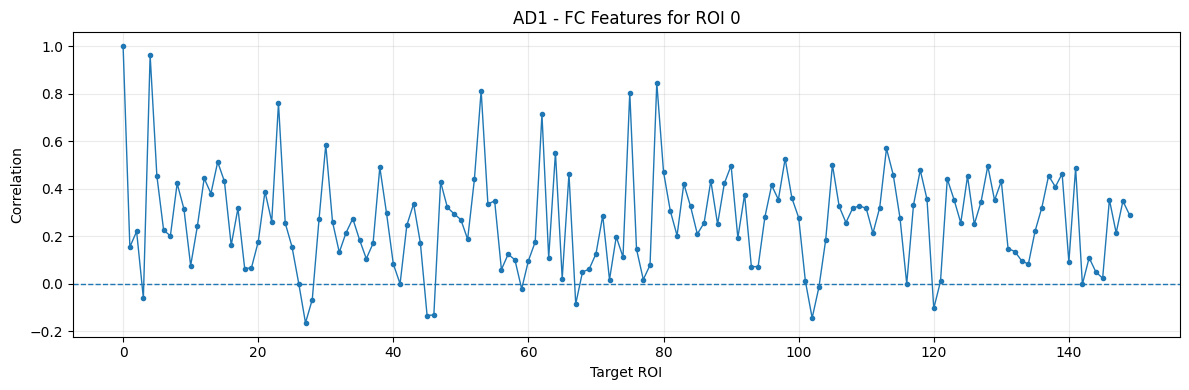

In [49]:
plot_fc_node_features(
    "FunctionalConnectivity.txt",
    subject="AD1",
    roi=0
)

In [52]:
subjects = (
    [f"AD{i}" for i in range(1, 11)] +
    [f"CN{i}" for i in range(1, 11)]
)

fc_processed = {}

for subject in subjects:

    path = os.path.join(
        DATA_ROOT,
        subject,
        "FunctionalConnectivity.txt"
    )

    fc = np.loadtxt(path)

    fc_processed[subject] = preprocess_fc(fc)

In [53]:
for subject in subjects:
    X = fc_processed[subject]
    print(subject, X.shape, "Diagonal max:", np.abs(np.diag(X)).max())

AD1 (150, 150) Diagonal max: 0.0
AD2 (150, 150) Diagonal max: 0.0
AD3 (150, 150) Diagonal max: 0.0
AD4 (150, 150) Diagonal max: 0.0
AD5 (150, 150) Diagonal max: 0.0
AD6 (150, 150) Diagonal max: 0.0
AD7 (150, 150) Diagonal max: 0.0
AD8 (150, 150) Diagonal max: 0.0
AD9 (150, 150) Diagonal max: 0.0
AD10 (150, 150) Diagonal max: 0.0
CN1 (150, 150) Diagonal max: 0.0
CN2 (150, 150) Diagonal max: 0.0
CN3 (150, 150) Diagonal max: 0.0
CN4 (150, 150) Diagonal max: 0.0
CN5 (150, 150) Diagonal max: 0.0
CN6 (150, 150) Diagonal max: 0.0
CN7 (150, 150) Diagonal max: 0.0
CN8 (150, 150) Diagonal max: 0.0
CN9 (150, 150) Diagonal max: 0.0
CN10 (150, 150) Diagonal max: 0.0


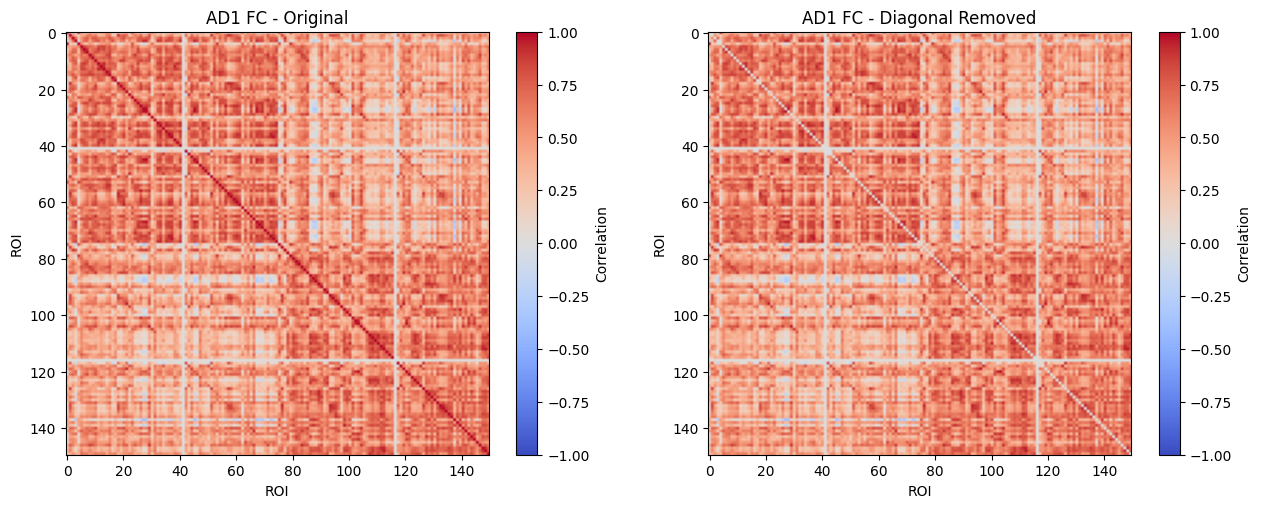

In [55]:
compare_fc_heatmap("AD1")

## 2.2 Structural Connectivity Preprocessing

The original structural connectivity (SC) matrix contains weighted streamline counts between ROIs. Before using SC as the graph adjacency matrix, the original diagonal values were removed because they do not represent meaningful connections between different ROIs.

$A_{ii}=0$

A controlled self-loop was then added to every node:

$\hat{A}=A+I$

The self-loops ensure that each ROI keeps its own information during graph convolution and also prevent isolated ROIs, such as ROI 41 and ROI 116, from having zero degree.

Next, the adjacency matrix was normalized using symmetric degree normalization:

$$
A_{\text{norm}}
=
\hat{D}^{-1/2}
\hat{A}
\hat{D}^{-1/2}
$$


This normalization rescales the SC edge weights according to the connectivity strength of the two connected ROIs. It prevents nodes with very large structural connection strengths from dominating the graph convolution and produces a numerically stable adjacency matrix for GCN message passing.

After normalization, the SC values became much smaller and more comparable across nodes and subjects. Therefore, an additional `log1p` transformation was not used in the final preprocessing pipeline.

The final normalized SC matrix, $A_{\text{norm}}$, was used as the adjacency matrix input to the GCN.







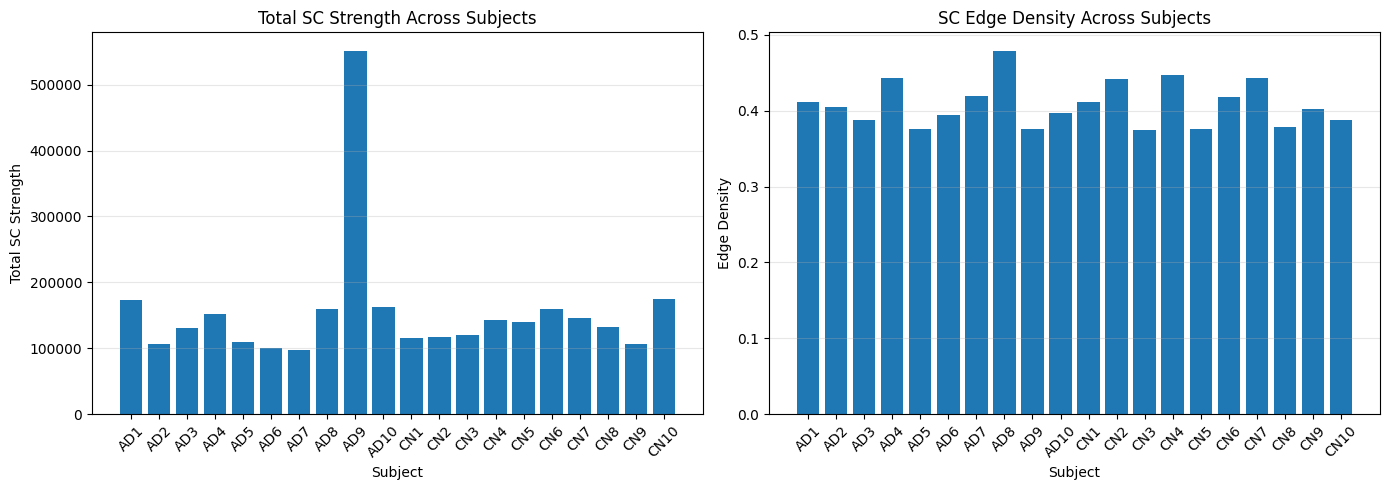

In [12]:
sc_stats_df = stats_graph_whole("StructuralConnectivity.txt")
stats_graph_whole_visualization(sc_stats_df)

Zero-degree ROIs: [ 41 116]


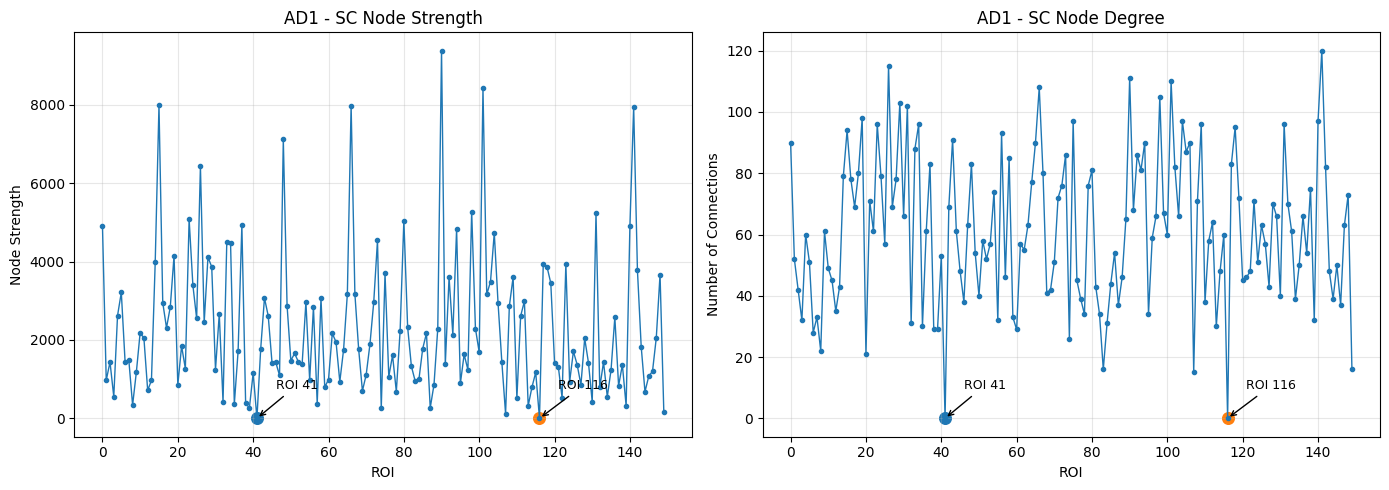

In [36]:
AD1_node_stats, AD1_zero_nodes = stats_graph_nodes(
    "StructuralConnectivity.txt",
    subject="AD1"
)
print("Zero-degree ROIs:", AD1_zero_nodes)

stats_graph_nodes_visualization(
    AD1_node_stats,
    AD1_zero_nodes,
    subject="AD1"
)

In [17]:
zero_node_results = check_zero_nodes_all_subjects(
    "StructuralConnectivity.txt"
)

AD1: [ 41 116]
AD2: [ 41 116]
AD3: [ 41 116]
AD4: [ 41 116]
AD5: [ 41 116]
AD6: [ 41 116]
AD7: [ 41 116]
AD8: [ 41 116]
AD9: [ 41 116]
AD10: [ 41 116]
CN1: [ 41 116]
CN2: [ 41 116]
CN3: [ 41 116]
CN4: [ 41 116]
CN5: [ 41 116]
CN6: [ 41 116]
CN7: [ 41 116]
CN8: [ 41 116]
CN9: [ 41 116]
CN10: [ 41 116]


In [28]:
subjects = (
    [f"AD{i}" for i in range(1, 11)] +
    [f"CN{i}" for i in range(1, 11)]
)

sc_processed = {}

for subject in subjects:
    path = os.path.join(
        DATA_ROOT,
        subject,
        "StructuralConnectivity.txt"
    )
    sc = np.loadtxt(path)
    sc_processed[subject] = preprocess_sc(sc)


for subject in subjects:
    A = sc_processed[subject]

    print(
        subject,
        A.shape,
        "NaN:", np.isnan(A).any(),
        "Inf:", np.isinf(A).any()
    )

AD1 (150, 150) NaN: False Inf: False
AD2 (150, 150) NaN: False Inf: False
AD3 (150, 150) NaN: False Inf: False
AD4 (150, 150) NaN: False Inf: False
AD5 (150, 150) NaN: False Inf: False
AD6 (150, 150) NaN: False Inf: False
AD7 (150, 150) NaN: False Inf: False
AD8 (150, 150) NaN: False Inf: False
AD9 (150, 150) NaN: False Inf: False
AD10 (150, 150) NaN: False Inf: False
CN1 (150, 150) NaN: False Inf: False
CN2 (150, 150) NaN: False Inf: False
CN3 (150, 150) NaN: False Inf: False
CN4 (150, 150) NaN: False Inf: False
CN5 (150, 150) NaN: False Inf: False
CN6 (150, 150) NaN: False Inf: False
CN7 (150, 150) NaN: False Inf: False
CN8 (150, 150) NaN: False Inf: False
CN9 (150, 150) NaN: False Inf: False
CN10 (150, 150) NaN: False Inf: False


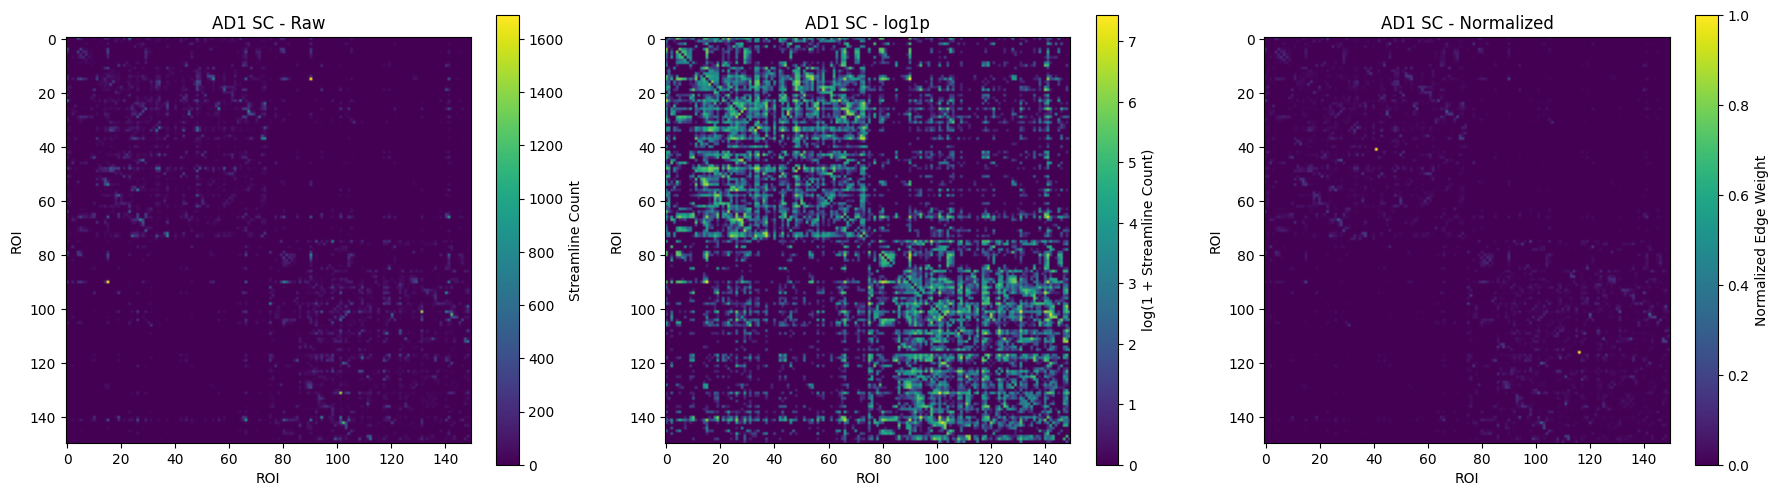

In [34]:
example_norm_demo(sc_processed)

# 3. Input Data Preparation & Modeling

## 3.1 Data Preparing

Each subject was represented as one graph sample containing:

- normalized SC adjacency matrix (A),

- FC node-feature matrix (X),

- binary class label (y).


Because the dataset contains only 20 subjects, a single train-test split could produce unstable results depending on which subjects were selected for testing. Therefore, stratified 5-fold cross-validation was used. Each fold contained approximately:

- 16 training subjects, (80%)

- 4 testing subjects, (20%)

- 2 AD and 2 CN subjects in each test fold.


The same five folds were fixed throughout the experiment so that every random seed was evaluated using exactly the same train-test subjects.

In [64]:
import torch
from sklearn.model_selection import StratifiedKFold

In [62]:
subjects = (
    [f"AD{i}" for i in range(1, 11)] +
    [f"CN{i}" for i in range(1, 11)]
)

graph_data = []

for subject in subjects:

    A = sc_processed[subject] ## weighted graph
    X = fc_processed[subject] ## node features with corelation.
    y = 1 if subject.startswith("AD") else 0

    graph_data.append({
        "subject": subject,
        "A": A,
        "X": X,
        "y": y
    })

print("Number of graph samples:", len(graph_data))

Number of graph samples: 20


In [63]:
graph_tensors = []

for graph in graph_data:

    graph_tensors.append({
        "subject": graph["subject"],
        "A": torch.tensor(
            graph["A"],
            dtype=torch.float32
        ),
        "X": torch.tensor(
            graph["X"],
            dtype=torch.float32
        ),
        "y": torch.tensor(
            graph["y"],
            dtype=torch.long
        )
    })

print("Number of graph samples:", len(graph_tensors))

print("A:", graph_tensors[0]["A"].shape)
print("X:", graph_tensors[0]["X"].shape)
print("y:", graph_tensors[0]["y"])

Number of graph samples: 20
A: torch.Size([150, 150])
X: torch.Size([150, 150])
y: tensor(1)


In [67]:
# --------------------------------------------------
# 2. Prepare labels for StratifiedKFold
# --------------------------------------------------

labels = [graph["y"].item() for graph in graph_tensors]

# --------------------------------------------------
# 3. 5-fold stratified cross-validation
# --------------------------------------------------

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

folds = []

for fold, (train_idx, test_idx) in enumerate(
    skf.split(graph_tensors, labels)
):

    train_data = [
        graph_tensors[i]
        for i in train_idx
    ]

    test_data = [
        graph_tensors[i]
        for i in test_idx
    ]

    folds.append({
        "fold": fold + 1,
        "train": train_data,
        "test": test_data
    })

    print(f"Fold {fold + 1}")
    print("Train size:", len(train_data))
    print("Test size :", len(test_data))

    print(
        "Train subjects:",
        [g["subject"] for g in train_data]
    )

    print(
        "Test subjects:",
        [g["subject"] for g in test_data]
    )

    print("-" * 60)

Fold 1
Train size: 16
Test size : 4
Train subjects: ['AD1', 'AD3', 'AD5', 'AD6', 'AD7', 'AD8', 'AD9', 'AD10', 'CN3', 'CN4', 'CN5', 'CN6', 'CN7', 'CN8', 'CN9', 'CN10']
Test subjects: ['AD2', 'AD4', 'CN1', 'CN2']
------------------------------------------------------------
Fold 2
Train size: 16
Test size : 4
Train subjects: ['AD1', 'AD2', 'AD3', 'AD4', 'AD5', 'AD7', 'AD8', 'AD10', 'CN1', 'CN2', 'CN3', 'CN4', 'CN6', 'CN7', 'CN8', 'CN9']
Test subjects: ['AD6', 'AD9', 'CN5', 'CN10']
------------------------------------------------------------
Fold 3
Train size: 16
Test size : 4
Train subjects: ['AD1', 'AD2', 'AD4', 'AD5', 'AD6', 'AD7', 'AD9', 'AD10', 'CN1', 'CN2', 'CN3', 'CN5', 'CN7', 'CN8', 'CN9', 'CN10']
Test subjects: ['AD3', 'AD8', 'CN4', 'CN6']
------------------------------------------------------------
Fold 4
Train size: 16
Test size : 4
Train subjects: ['AD1', 'AD2', 'AD3', 'AD4', 'AD6', 'AD7', 'AD8', 'AD9', 'CN1', 'CN2', 'CN3', 'CN4', 'CN5', 'CN6', 'CN8', 'CN10']
Test subjects: ['A

## 3.2 Modeling
*A two-layer Graph Convolutional Network was used for graph-level binary classification.*

**Input:**  
The input to the model consists of: $X \in \mathbb{R}^{150\times150}$ and $A \in \mathbb{R}^{150\times150}$

- where FC provides node features and SC determines how information propagates between ROIs.

**Structure:**  
The main graph convolution operation can be represented as:
$H = \sigma(A X W)$

- where (W) is a learnable weight matrix and $\sigma$ represents the ReLU activation function.

The overall architecture was:
$$
150\rightarrow64\rightarrow64\rightarrow\text{Global Mean Pooling}\rightarrow
2
$$

After the two graph convolution layers, global mean pooling was used to average the representations of all 150 ROIs into one graph-level feature vector.

The final linear layer outputs two logits corresponding to:

- class 0: CN

- class 1: AD


In [ ]:
# The GCN passes the FC information through the SC network.

In [68]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [69]:
class GCNClassifier(nn.Module):
  def __init__(self, input_dim=150, hidden_dim=64, output_dim=2):
        super().__init__()
        self.gcn1 = nn.Linear(input_dim,hidden_dim, bias=False)
        self.gcn2 = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.classifier = nn.Linear( hidden_dim, output_dim)


  def forward(self, X, A):

        # -------------------------
        # GCN Layer 1
        # -------------------------
        H = self.gcn1(X)
        # Pass information through graph
        H = A @ H
        # Non-linearity
        H = F.relu(H)
        # -------------------------
        # GCN Layer 2
        # -------------------------
        H = self.gcn2(H)
        # Pass information through graph again
        H = A @ H
        H = F.relu(H)


        # -------------------------
        # Graph-level pooling
        # -------------------------
        H_graph = H.mean(dim=0)

        # -------------------------
        # Classification
        # -------------------------
        output = self.classifier(H_graph)

        return output

In [73]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

# 4. Training Model and Experiment


The model was trained using the Adam optimizer with:

- learning rate: (0.001),

- weight decay: $10^{-4}$,

- number of epochs: 50,

- hidden dimension: 64,

- loss function: cross-entropy loss.

Five random seeds were evaluated:$42,\ 123,\ 2026,\ 7,\ 99$

For every seed, the same fixed 5-fold cross-validation partition was used. A completely new GCN model was initialized and trained for each fold.

Therefore, the full experiment trained:
$5\text{ seeds}\times5\text{ folds}=25\text{ models}$

Each subject received exactly one out-of-fold prediction for each random seed. Predictions from all five folds were combined to calculate seed-level performance metrics across all 20 subjects.


In [88]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix
)

from scipy.stats import t

In [89]:
seeds = [42, 123, 2026, 7, 99]

In [107]:
results = []
roc_results = []
all_predictions = {}

num_epochs = 50

for seed in seeds:
  print("=" * 60)
  print(f"SEED {seed}")
  print("=" * 60)

  seed_true = []
  seed_pred = []
  seed_prob = []
  seed_subjects = []

  for fold_data in folds:
    fold_number = fold_data["fold"]
    train_data = fold_data["train"]
    test_data = fold_data["test"]

    print(f"\nFold {fold_number}")

    # --------------------------------
    # Train new model on this fold
    # --------------------------------
    model, loss_history = train_one_fold(
        train_data=train_data,
        seed=seed,
        num_epochs=num_epochs
        )

    # --------------------------------
    # Evaluate this fold
    # --------------------------------
    subjects_fold, true_fold, pred_fold, prob_fold = evaluate_one_fold(model,test_data)

    seed_subjects.extend(subjects_fold)
    seed_true.extend(true_fold)
    seed_pred.extend(pred_fold)
    seed_prob.extend(prob_fold)

    fold_accuracy = accuracy_score(true_fold,pred_fold)

    print(f"Test subjects: {subjects_fold}")

    print(f"Fold accuracy: {fold_accuracy:.3f}")

  # ==================================================
  # Evaluate all 20 out-of-fold predictions
  # ==================================================

  metrics = calculate_metrics(seed_true, seed_pred, seed_prob)

  results.append({
          "seed": seed,
          "accuracy": metrics["accuracy"],
          "f1": metrics["f1"],
          "auc": metrics["auc"],
          "sensitivity": metrics["sensitivity"],
          "specificity": metrics["specificity"]
      })

  # --------------------------------
  # ROC curve
  # --------------------------------
  fpr, tpr, thresholds = roc_curve(seed_true,seed_prob)

  roc_results.append({
      "seed": seed,
      "fpr": fpr,
        "tpr": tpr,
        "auc": metrics["auc"]
      })

  # --------------------------------
  # Save subject predictions
  # --------------------------------
  all_predictions[seed] = pd.DataFrame({
      "subject": seed_subjects,
      "true_label": seed_true,
      "predicted_label": seed_pred,
      "probability_AD": seed_prob
      })

  # --------------------------------
  # Print seed results
  # --------------------------------
  print("\nOverall Result")

  print(f"Accuracy    : {metrics['accuracy']:.3f}")
  print(f"F1          : {metrics['f1']:.3f}")
  print(f"AUROC       : {metrics['auc']:.3f}")
  print(f"Sensitivity : {metrics['sensitivity']:.3f}")
  print(f"Specificity : {metrics['specificity']:.3f}")
  print("\nConfusion Matrix")
  print(metrics["confusion_matrix"])


SEED 42

Fold 1
Epoch   1/50 | Loss: 0.7872
Epoch   5/50 | Loss: 0.6929
Epoch  10/50 | Loss: 0.6855
Epoch  15/50 | Loss: 0.6616
Epoch  20/50 | Loss: 0.6412
Epoch  25/50 | Loss: 0.6346
Epoch  30/50 | Loss: 0.6462
Epoch  35/50 | Loss: 0.5486
Epoch  40/50 | Loss: 0.4336
Epoch  45/50 | Loss: 0.3439
Epoch  50/50 | Loss: 0.2729
Test subjects: ['AD2', 'AD4', 'CN1', 'CN2']
Fold accuracy: 0.500

Fold 2
Epoch   1/50 | Loss: 0.7808
Epoch   5/50 | Loss: 0.6930
Epoch  10/50 | Loss: 0.6843
Epoch  15/50 | Loss: 0.6556
Epoch  20/50 | Loss: 0.6304
Epoch  25/50 | Loss: 0.6128
Epoch  30/50 | Loss: 0.5956
Epoch  35/50 | Loss: 0.5535
Epoch  40/50 | Loss: 0.4933
Epoch  45/50 | Loss: 0.4645
Epoch  50/50 | Loss: 0.4526
Test subjects: ['AD6', 'AD9', 'CN5', 'CN10']
Fold accuracy: 0.750

Fold 3
Epoch   1/50 | Loss: 0.7736
Epoch   5/50 | Loss: 0.6955
Epoch  10/50 | Loss: 0.6854
Epoch  15/50 | Loss: 0.6512
Epoch  20/50 | Loss: 0.6363
Epoch  25/50 | Loss: 0.5931
Epoch  30/50 | Loss: 0.5649
Epoch  35/50 | Loss: 0.57

# 5. Evaluation

The model was evaluated using accuracy, F1 score, area under the receiver operating characteristic curve (AUROC), sensitivity, and specificity.

The five random-seed experiments produced the following results:

| Seed | Accuracy | F1    | AUROC | Sensitivity | Specificity |
|-----:|---------:|------:|------:|------------:|------------:|
| 42   | 0.70     | 0.667 | 0.67  | 0.60        | 0.80        |
| 123  | 0.70     | 0.667 | 0.67  | 0.60        | 0.80        |
| 2026 | 0.65     | 0.632 | 0.68  | 0.60        | 0.70        |
| 7    | 0.75     | 0.706 | 0.69  | 0.60        | 0.90        |
| 99   | 0.70     | 0.667 | 0.69  | 0.60        | 0.80        |


```
accuracy: 0.700 ± 0.035
f1: 0.667 ± 0.026
auc: 0.680 ± 0.010
sensitivity: 0.600 ± 0.000
specificity: 0.800 ± 0.071
```

In [108]:
results_df = pd.DataFrame(results)
results_df

,seed,accuracy,f1,auc,sensitivity,specificity
0,42,0.70,0.666667,0.67,0.6,0.8
1,123,0.70,0.666667,0.67,0.6,0.8
2,2026,0.65,0.631579,0.68,0.6,0.7
3,7,0.75,0.705882,0.69,0.6,0.9
4,99,0.70,0.666667,0.69,0.6,0.8


In [109]:
results_df.mean(numeric_only=True).round(3)
for col in ["accuracy", "f1", "auc", "sensitivity", "specificity"]:
    print(
        f"{col}: "
        f"{results_df[col].mean():.3f} ± "
        f"{results_df[col].std():.3f}"
    )

accuracy: 0.700 ± 0.035
f1: 0.667 ± 0.026
auc: 0.680 ± 0.010
sensitivity: 0.600 ± 0.000
specificity: 0.800 ± 0.071


# 6. Conclusion

This project constructed a multimodal graph-based representation of brain connectivity for AD versus CN classification. Structural connectivity was used as the graph adjacency matrix, while functional connectivity was used as node-level features.

SC preprocessing removed the original diagonal, introduced standardized self-loops, and applied symmetric graph normalization. This procedure prevented zero-degree numerical problems and prepared the weighted structural graph for GCN message passing. FC was used as the node-feature matrix after removing self-correlations.

A two-layer GCN was evaluated using fixed stratified 5-fold cross-validation across five random seeds. The model achieved an average accuracy of approximately $0.700 \pm 0.035$ and an AUROC of $0.680 \pm 0.010$.

These results suggest that the combination of structural and functional brain connectivity contains useful information for distinguishing AD from cognitively normal subjects. However, because only 20 subjects were available, the results should be interpreted as a small-sample experimental demonstration rather than evidence of clinically reliable diagnostic performance. A larger dataset would be necessary to evaluate the generalizability of the model more confidently.

# Appendex I Code

In [43]:
def example(file):
    print(f"==============={file}==================")
    AD1 = np.loadtxt(
    os.path.join(DATA_ROOT, "AD1", file)
)

    print("Shape:", AD1.shape)
    print("Min:", AD1.min())
    print("Max:", AD1.max())
    print("Symmetric:", np.allclose(AD1, AD1.T))


def example_graph_comparing(file,text):
    AD1_sc = np.loadtxt(os.path.join(DATA_ROOT, "AD1", file))
    # Keep original data unchanged
    sc_raw = AD1_sc.copy()
    # Remove original SC diagonal
    np.fill_diagonal(sc_raw, 0)
    # Compress large streamline counts
    sc_log = np.log1p(sc_raw)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Raw SC
    im1 = axes[0].imshow(
        sc_raw,
        cmap="viridis"
    )

    axes[0].set_title(f"AD1 {text} - Raw")
    axes[0].set_xlabel("ROI")
    axes[0].set_ylabel("ROI")

    plt.colorbar(
        im1,
        ax=axes[0],
        label="Streamline Count"
    )

    # log1p SC
    im2 = axes[1].imshow(
        sc_log,
        cmap="viridis"
    )

    axes[1].set_title(f"AD1 {text} - log1p")
    axes[1].set_xlabel("ROI")
    axes[1].set_ylabel("ROI")

    plt.colorbar(
        im2,
        ax=axes[1],
        label="log(1 + Streamline Count)"
    )

    plt.tight_layout()
    plt.show()

In [54]:
def inspect_fc_node(file, subject="AD1", roi=0):

    path = os.path.join(
        DATA_ROOT,
        subject,
        file
    )

    fc = np.loadtxt(path)

    feature_vector = fc[roi]

    print("Subject:", subject)
    print("ROI:", roi)
    print("Feature vector shape:", feature_vector.shape)
    print("First 10 values:")
    print(feature_vector[:10])

    return feature_vector

def plot_fc_node_features(
    file,
    subject="AD1",
    roi=0
):

    path = os.path.join(
        DATA_ROOT,
        subject,
        file
    )

    fc = np.loadtxt(path)

    features = fc[roi]

    plt.figure(figsize=(12, 4))

    plt.plot(
        np.arange(len(features)),
        features,
        marker="o",
        markersize=3,
        linewidth=1
    )

    plt.axhline(
        0,
        linestyle="--",
        linewidth=1
    )

    plt.xlabel("Target ROI")
    plt.ylabel("Correlation")
    plt.title(
        f"{subject} - FC Features for ROI {roi}"
    )

    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


def preprocess_fc(fc):

    X = fc.copy()

    # remove self-correlation
    np.fill_diagonal(X, 0)

    return X




def compare_fc_heatmap(subject="AD1"):
    # Load original FC
    fc_original = np.loadtxt(
        os.path.join(
            DATA_ROOT,
            subject,
            "FunctionalConnectivity.txt"
        )
    )

    # Processed FC
    fc_clean = fc_processed[subject]

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Original FC
    im1 = axes[0].imshow(
        fc_original,
        cmap="coolwarm",
        vmin=-1,
        vmax=1
    )

    axes[0].set_title(f"{subject} FC - Original")
    axes[0].set_xlabel("ROI")
    axes[0].set_ylabel("ROI")

    plt.colorbar(
        im1,
        ax=axes[0],
        label="Correlation"
    )

    # Diagonal removed
    im2 = axes[1].imshow(
        fc_clean,
        cmap="coolwarm",
        vmin=-1,
        vmax=1
    )

    axes[1].set_title(f"{subject} FC - Diagonal Removed")
    axes[1].set_xlabel("ROI")
    axes[1].set_ylabel("ROI")

    plt.colorbar(
        im2,
        ax=axes[1],
        label="Correlation"
    )

    plt.tight_layout()
    plt.show()

In [13]:
def stats_graph_nodes(file, subject="AD1"):

    path = os.path.join(
        DATA_ROOT,
        subject,
        file
    )

    sc = np.loadtxt(path)

    # Keep original unchanged
    sc = sc.copy()

    # Remove original diagonal
    np.fill_diagonal(sc, 0)

    # Node strength:
    # sum of all edge weights connected to each ROI
    node_strength = sc.sum(axis=1)

    # Node degree:
    # number of non-zero connections for each ROI
    node_degree = np.sum(sc > 0, axis=1)

    # Find disconnected nodes
    zero_nodes = np.where(node_degree == 0)[0]

    stats_df = pd.DataFrame({
        "ROI": np.arange(sc.shape[0]),
        "strength": node_strength,
        "degree": node_degree
    })

    return stats_df, zero_nodes


def stats_graph_nodes_visualization(
    node_stats_df,
    zero_nodes,
    subject="AD1"
):

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # -----------------------------
    # Left: Node Strength
    # -----------------------------
    axes[0].plot(
        node_stats_df["ROI"],
        node_stats_df["strength"],
        marker="o",
        markersize=3,
        linewidth=1
    )

    axes[0].set_title(f"{subject} - SC Node Strength")
    axes[0].set_xlabel("ROI")
    axes[0].set_ylabel("Node Strength")
    axes[0].grid(alpha=0.3)

    # Highlight zero nodes
    for roi in zero_nodes:

        axes[0].scatter(
            roi,
            0,
            s=70
        )

        axes[0].annotate(
            f"ROI {roi}",
            xy=(roi, 0),
            xytext=(roi + 5, node_stats_df["strength"].max() * 0.08),
            arrowprops=dict(arrowstyle="->"),
            fontsize=9
        )


    # -----------------------------
    # Right: Node Degree
    # -----------------------------
    axes[1].plot(
        node_stats_df["ROI"],
        node_stats_df["degree"],
        marker="o",
        markersize=3,
        linewidth=1
    )

    axes[1].set_title(f"{subject} - SC Node Degree")
    axes[1].set_xlabel("ROI")
    axes[1].set_ylabel("Number of Connections")
    axes[1].grid(alpha=0.3)

    for roi in zero_nodes:

        axes[1].scatter(
            roi,
            0,
            s=70
        )

        axes[1].annotate(
            f"ROI {roi}",
            xy=(roi, 0),
            xytext=(roi + 5, node_stats_df["degree"].max() * 0.08),
            arrowprops=dict(arrowstyle="->"),
            fontsize=9
        )

    plt.tight_layout()
    plt.show()

In [27]:
def stats_graph_whole(file):
    subjects = (
        [f"AD{i}" for i in range(1, 11)] +
        [f"CN{i}" for i in range(1, 11)]
    )

    stats = []

    for subject in subjects:

        path = os.path.join(
            DATA_ROOT,
            subject,
            file # file type
        )

        sc = np.loadtxt(path)

        # Remove diagonal
        np.fill_diagonal(sc, 0)

        # Unique edges only
        upper = sc[np.triu_indices_from(sc, k=1)]

        nonzero_edges = upper[upper > 0]
        stats.append({
            "subject": subject,
            "group": "AD" if subject.startswith("AD") else "CN",

            # total edge weight
            "total_strength": upper.sum(),

            # percentage of possible edges that exist
            "edge_density": np.mean(upper > 0),

            "mean_nonzero_strength": nonzero_edges.mean(),
            "max_strength": upper.max()
        })

    stats_df = pd.DataFrame(stats)
    return stats_df


def stats_graph_whole_visualization(sc_stats_df):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # -----------------------------
    # Left: Total SC Strength
    # -----------------------------
    axes[0].bar(
        sc_stats_df["subject"],
        sc_stats_df["total_strength"]
    )

    axes[0].set_title("Total SC Strength Across Subjects")
    axes[0].set_xlabel("Subject")
    axes[0].set_ylabel("Total SC Strength")
    axes[0].tick_params(axis="x", rotation=45)
    axes[0].grid(axis="y", alpha=0.3)


    # -----------------------------
    # Right: Edge Density
    # -----------------------------
    axes[1].bar(
        sc_stats_df["subject"],
        sc_stats_df["edge_density"]
    )

    axes[1].set_title("SC Edge Density Across Subjects")
    axes[1].set_xlabel("Subject")
    axes[1].set_ylabel("Edge Density")
    axes[1].tick_params(axis="x", rotation=45)
    axes[1].grid(axis="y", alpha=0.3)


    plt.tight_layout()
    plt.show()


def check_zero_nodes_all_subjects(file):

    subjects = (
        [f"AD{i}" for i in range(1, 11)] +
        [f"CN{i}" for i in range(1, 11)]
    )

    results = {}

    for subject in subjects:

        node_stats, zero_nodes = stats_graph_nodes(
            file,
            subject
        )

        results[subject] = zero_nodes

        print(
            f"{subject}: {zero_nodes}"
        )

    return results



def preprocess_sc(sc):

    A = sc.copy()

    # Remove original diagonal
    np.fill_diagonal(A, 0)

    # Add controlled self-loops
    A_hat = A + np.eye(A.shape[0])

    # Degree / strength
    degree = A_hat.sum(axis=1)

    # Symmetric normalization
    D_inv_sqrt = np.diag(
        1.0 / np.sqrt(degree)
    )

    A_norm = (
        D_inv_sqrt
        @ A_hat
        @ D_inv_sqrt
    )

    return A_norm



In [33]:
def example_norm_demo(sc_processed):
  AD1_sc = np.loadtxt(
      os.path.join(
          DATA_ROOT,
          "AD1",
          "StructuralConnectivity.txt"
      )
  )

  # -----------------------------
  # Stage 1: Raw SC
  # -----------------------------
  sc_raw = AD1_sc.copy()

  # Remove original diagonal
  np.fill_diagonal(sc_raw, 0)

  # -----------------------------
  # Stage 2: log1p SC
  # -----------------------------
  sc_log = np.log1p(sc_raw)

  # -----------------------------
  # Stage 3: Final processed SC
  # -----------------------------
  sc_final = sc_processed["AD1"]



  fig, axes = plt.subplots(1, 3, figsize=(18, 5))


  # Raw SC
  im1 = axes[0].imshow(
      sc_raw,
      cmap="viridis"
  )

  axes[0].set_title("AD1 SC - Raw")
  axes[0].set_xlabel("ROI")
  axes[0].set_ylabel("ROI")

  plt.colorbar(
      im1,
      ax=axes[0],
      label="Streamline Count"
  )


  # log1p SC
  im2 = axes[1].imshow(
      sc_log,
      cmap="viridis"
  )

  axes[1].set_title("AD1 SC - log1p")
  axes[1].set_xlabel("ROI")
  axes[1].set_ylabel("ROI")

  plt.colorbar(
      im2,
      ax=axes[1],
      label="log(1 + Streamline Count)"
  )


  # Final normalized adjacency
  im3 = axes[2].imshow(
      sc_final,
      cmap="viridis"
  )

  axes[2].set_title("AD1 SC - Normalized")
  axes[2].set_xlabel("ROI")
  axes[2].set_ylabel("ROI")

  plt.colorbar(
      im3,
      ax=axes[2],
      label="Normalized Edge Weight"
  )


  plt.tight_layout()
  plt.show()

In [91]:
def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)






def train_one_fold(
    train_data,
    seed,
    num_epochs=30,
    learning_rate=0.001,
    weight_decay=1e-4
):

    # Reset random state
    set_seed(seed)

    # Brand-new model for this fold
    model = GCNClassifier(
        input_dim=150,
        hidden_dim=64,
        output_dim=2
    )

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    loss_history = []

    for epoch in range(num_epochs):

        model.train()

        total_loss = 0

        # Train on all subjects in training fold
        for sample in train_data:

            X = sample["X"]
            A = sample["A"]
            y = sample["y"]

            optimizer.zero_grad()

            output = model(X, A)

            loss = criterion(
                output.unsqueeze(0),
                y.unsqueeze(0)
            )

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_data)

        loss_history.append(avg_loss)

        # Print training progress
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"Epoch {epoch + 1:3d}/{num_epochs} "
                f"| Loss: {avg_loss:.4f}")

    return model, loss_history




def evaluate_one_fold(model, test_data):

    model.eval()

    y_true = []
    y_pred = []
    y_prob = []
    subjects = []

    with torch.no_grad():

        for sample in test_data:

            X = sample["X"]
            A = sample["A"]
            y = sample["y"]

            output = model(X, A)

            # Convert logits to probabilities
            probabilities = torch.softmax(
                output,
                dim=0
            )

            # Probability of class 1 = AD
            prob_ad = probabilities[1].item()

            prediction = torch.argmax(
                output
            ).item()

            y_true.append(y.item())
            y_pred.append(prediction)
            y_prob.append(prob_ad)
            subjects.append(sample["subject"])

    return subjects, y_true, y_pred, y_prob


def calculate_metrics(y_true, y_pred, y_prob):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    f1 = f1_score(
        y_true,
        y_pred
    )

    auc = roc_auc_score(
        y_true,
        y_prob
    )

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    tn, fp, fn, tp = cm.ravel()

    sensitivity = tp / (tp + fn)

    specificity = tn / (tn + fp)

    return {
        "accuracy": accuracy,
        "f1": f1,
        "auc": auc,
        "sensitivity": sensitivity,
        "specificity": specificity,
        "confusion_matrix": cm
    }